# 03 — Do late deliveries hurt reviews?

**Leadership question:** Do late deliveries lead to worse customer reviews?

## Definitions
- **Late** = delivered *date* is after the promised *date* (dates compared, not timestamps)
- **Days late** = delivered date − promised date (negative = early)
- **Population:** delivered orders with a delivery date and a review, Jan 2017 – Aug 2018
- **Grain:** one row per order (if an order has several reviews, their scores are averaged)
- **Metrics:** average review score; share of bad reviews (1–2 stars)
- **Excluded:** orders never delivered (no delivery date), reported separately because they may be the angriest customers (selection bias)

In [1]:
from pathlib import Path
import duckdb

con = duckdb.connect(str(Path("../data/olist.duckdb")), read_only=True)

orders = con.sql("""
WITH reviews AS (                          -- step 1: one review score per order
    SELECT order_id, AVG(review_score) AS review_score
    FROM raw.order_reviews
    GROUP BY order_id
),
delivered AS (                             -- step 2: delivered orders + days late
    SELECT o.order_id,
           c.customer_state,
           DATE_DIFF('day',
                     CAST(o.order_estimated_delivery_date AS DATE),
                     CAST(o.order_delivered_customer_date AS DATE)) AS days_late,
           r.review_score
    FROM raw.orders o
    JOIN raw.customers c ON o.customer_id = c.customer_id
    JOIN reviews r       ON o.order_id = r.order_id
    WHERE o.order_status = 'delivered'
      AND o.order_delivered_customer_date IS NOT NULL
      AND o.order_purchase_timestamp >= '2017-01-01'
      AND o.order_purchase_timestamp <  '2018-09-01'
)
SELECT *,                                  -- step 3: label each order
       CASE WHEN days_late <= 0 THEN '0: on time'
            WHEN days_late <= 3 THEN '1: 1-3 days late'
            WHEN days_late <= 7 THEN '2: 4-7 days late'
            ELSE                     '3: 8+ days late'
       END AS delivery_bucket,
       review_score <= 2 AS bad_review
FROM delivered
""").df()

print(f"{len(orders):,} orders")
orders.head()

95,560 orders


,order_id,customer_state,days_late,review_score,delivery_bucket,bad_review
0,00e7ee1b050b8499577073aeb2a297a1,SP,-11,4.0,0: on time,False
1,29150127e6685892b6eab3eec79f59c7,SP,-8,5.0,0: on time,False
2,b2059ed67ce144a36e2aa97d2c9e9ad2,SP,1,5.0,1: 1-3 days late,False
3,951670f92359f4fe4a63112aa7306eba,SP,-13,5.0,0: on time,False
4,6b7d50bd145f6fc7f33cebabd7e49d0f,SP,-6,5.0,0: on time,False


In [2]:
summary = (orders.groupby("delivery_bucket")
                 .agg(orders=("order_id", "count"),
                      avg_score=("review_score", "mean"),
                      bad_review_pct=("bad_review", "mean"))
                 .reset_index())
summary["share_of_orders_pct"] = summary["orders"] / summary["orders"].sum() * 100
summary["bad_review_pct"] *= 100
summary.round(2)

,delivery_bucket,orders,avg_score,bad_review_pct,share_of_orders_pct
0,0: on time,89182,4.29,9.21,93.33
1,1: 1-3 days late,1851,3.29,32.20,1.94
2,2: 4-7 days late,1748,2.11,67.56,1.83
3,3: 8+ days late,2779,1.70,79.17,2.91


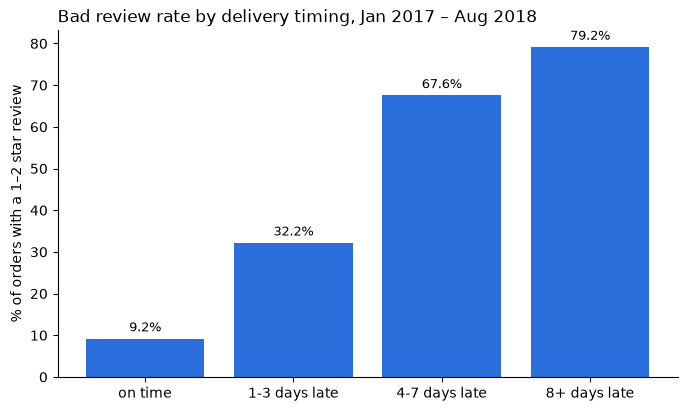

In [3]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(summary["delivery_bucket"].str[3:], summary["bad_review_pct"], color="#2a6fdb")
ax.bar_label(bars, fmt="%.1f%%", padding=3, fontsize=9)
ax.set_ylabel("% of orders with a 1–2 star review")
ax.set_title("Bad review rate by delivery timing, Jan 2017 – Aug 2018", loc="left")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

In [4]:
orders["is_late"] = orders["days_late"] > 0

g = orders.groupby(["customer_state", "is_late"])["bad_review"]
state = g.mean().unstack() * 100
state.columns = ["on_time_bad_pct", "late_bad_pct"]
state["late_orders"] = g.count().unstack()[True]

state = state[state["late_orders"] >= 100].sort_values("late_orders", ascending=False)
state["late_worse"] = state["late_bad_pct"] > state["on_time_bad_pct"]
state.round(1)

,on_time_bad_pct,late_bad_pct,late_orders,late_worse
customer_state,,,,
SP,8.6,54.3,1783,True
RJ,10.9,73.0,1456,True
MG,9.5,58.8,505,True
BA,11.2,60.2,384,True
RS,8.5,64.2,321,True
SC,8.9,59.9,284,True
ES,8.9,56.1,205,True
PR,9.1,52.1,194,True
CE,9.1,68.4,174,True


In [5]:
undelivered = con.sql("""
WITH reviews AS (
    SELECT order_id, AVG(review_score) AS review_score
    FROM raw.order_reviews
    GROUP BY order_id
)
SELECT COUNT(*)                                            AS orders,
       AVG(r.review_score)                                 AS avg_score,
       AVG(CASE WHEN r.review_score <= 2 THEN 1 ELSE 0 END) * 100 AS bad_review_pct
FROM raw.orders o
JOIN reviews r ON o.order_id = r.order_id
WHERE o.order_delivered_customer_date IS NULL
  AND o.order_purchase_timestamp >= '2017-01-01'
  AND o.order_purchase_timestamp <  '2018-09-01'
""").df()
undelivered.round(2)

,orders,avg_score,bad_review_pct
0,2769,1.76,77.46


## Findings
- **Yes, late deliveries strongly hurt reviews.** On-time orders get 9.2% bad (1–2 star) reviews; 1–3 days late → 32.2%; 4–7 days → 67.6%; 8+ days → 79.2%. Average score falls from 4.29 to 1.70.
- **Even small delays matter.** Just 1–3 days late more than triples the bad-review rate, so *keeping the promise* matters, not only speed.
- **Large impact from a small share.** Late orders are 6.7% of delivered orders but generate about a third of all bad reviews.
- **Undelivered orders are even worse.** 2,769 reviewed orders never arrived: average 1.76, 77.5% bad reviews. Together, late and undelivered orders account for roughly 40% of bad reviews.

## How confident are we? (correlation vs. causation)
- **Dose-response:** every extra step of lateness worsens reviews.
- **Like with like:** in all 14 states with 100+ late orders, late orders score far worse (≈ 52–73% vs. 8–11% bad), so region is not the explanation.
- **Plausible mechanism:** waiting past the promised date frustrates customers.
- Without a controlled experiment this is strong evidence, not proof.

**Recommendation:** prioritize on-time delivery, e.g. more realistic promised dates and better carrier performance in high-volume states.